# PBMC dataset (two batches: 10x 3' and 10x 5')

Loads `/gpfs01/berens/user/sdamrich/data/ne_aligned/PBMC`: 33694 genes x 15476 human
peripheral blood mononuclear cells, split over two batches that differ by chemistry.

| file | contents |
| --- | --- |
| `b1_exprs.txt.gz` / `b2_exprs.txt.gz` | tab-separated raw counts, genes as rows, cells as columns |
| `b1_celltype.txt.gz` / `b2_celltype.txt.gz` | one row per cell of that batch, cell ids as row names |

Same file layout as [load_hematopoietic.ipynb](load_hematopoietic.ipynb), so this notebook is
its close sibling. `b1` is the 10x 3' run (`data_3p`, 8098 cells) and `b2` the 10x 5' run
(`data_5p`, 7378 cells). Both are on exactly the same 33694 genes and all 9 cell types occur
in both batches, so unlike the hematopoietic dataset there is only one variant (`.../PBMC`)
and no "shared cell types" version.

The preprocessing lives in [preprocessing.py](../src/ne_aligned_utils/preprocessing.py) and
the inspection plots in [plot.py](../src/ne_aligned_utils/plot.py), shared with the other
`load_*` notebooks: Seurat-style filtering, `seurat_v3` HVG selection of 1000 genes,
library-size normalisation + `log1p`, saved as `X1.npy` / `X2.npy` / `X1_counts.npy` /
`X2_counts.npy` / `labels*.npy` / ... so the `compute_aligned_*` scripts can pick the dataset
up from a plain `dataset` string.

In [1]:
%load_ext autoreload
%autoreload 2

import gzip
import os
from itertools import islice

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix

from ne_aligned_utils.plot import plot_variant
from ne_aligned_utils.preprocessing import check_saved, describe_batches, prepare

In [ ]:
base_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned"

dataset = "PBMC"
data_path = os.path.join(base_path, dataset)  # raw .txt.gz files live here
res_path_all = data_path                      # ... and the derived arrays go back into it
fig_path = os.path.join(base_path, "figures")

os.makedirs(fig_path, exist_ok=True)  # res_path_all is created by `prepare`

sorted(os.listdir(data_path))

['X1.npy',
 'X1_counts.npy',
 'X2.npy',
 'X2_counts.npy',
 'b1_celltype.txt.gz',
 'b1_exprs.txt.gz',
 'b2_celltype.txt.gz',
 'b2_exprs.txt.gz',
 'cell_type_names.npy',
 'cells_metadata.csv',
 'combined_1000genes.h5ad',
 'dataset_names.npy',
 'features.txt',
 'labels1.npy',
 'labels2.npy']

## Raw loading

The layout of these files is not documented anywhere, so the next cell prints the first two
lines of each of them. They turn out to be:

- `b*_exprs.txt.gz`: the header is one field short of the data rows, i.e. gene names as an
  unnamed index column and cell ids as the column names.
- `b*_celltype.txt.gz`: cell ids as an unnamed index column plus `Sample`, `n_counts`,
  `n_genes`, `batch`, `louvain`, `anno`, `Method`, `CellType`. `CellType` provides the labels
  and the rest is carried along into `cells_metadata.csv`.

`read_batch` picks the cell-type column by name and aligns the table to the columns of the
count matrix by cell id, falling back to the row order if the ids do not match.

In [ ]:
for f in sorted(os.listdir(data_path)):
    if not f.endswith(".txt.gz"):
        continue
    with gzip.open(os.path.join(data_path, f), "rt") as fh:
        head = [line.rstrip("\n") for line in islice(fh, 2)]
    print(f"--- {f} ---")
    for line in head:
        print("   ", line[:200] + (" ..." if len(line) > 200 else ""))
    n_fields = [len(line.split("\t")) for line in head]
    if len(n_fields) == 2 and n_fields[1] == n_fields[0] + 1:
        print(f"    fields per line: {n_fields} -> header one short, the index column is unnamed")
    else:
        print(f"    fields per line: {n_fields}")
    print()

--- b1_celltype.txt.gz ---
    	Sample	n_counts	n_genes	batch	louvain	anno	Method	CellType
    data_3p-AAACCTGAGCATCATC-0	data_3p	2394	871	0	9	B cell	10X_3prime	B cell
    fields per line: [9, 9]

--- b1_exprs.txt.gz ---
    	data_3p-AAACCTGAGCATCATC-0	data_3p-AAACCTGAGCTAGTGG-0	data_3p-AAACCTGCACATTAGC-0	data_3p-AAACCTGCACTGTTAG-0	data_3p-AAACCTGCATAGTAAG-0	data_3p-AAACCTGCATGAACCT-0	data_3p-AAACCTGGTAAGAGGA-0	data_3p-AA ...
    RP11-34P13.3	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0 ...
    fields per line: [8099, 8099]

--- b2_celltype.txt.gz ---
    	Sample	n_counts	n_genes	batch	louvain	anno	Method	CellType
    data_5p-AAACCTGAGCGATAGC-1	data_5p	2712	1318	1	18	NK cell	10X_5prime	NK cell
    fields per line: [9, 9]

--- b2_exprs.txt.gz ---
    	data_5p-AAACCTGAGCGATAGC-1	data_5p-AAACCTGAGCTAAACA-1	data_5p-AAACCTGAGGGAGTAA-1	data_5p-AAACCTG

In [4]:
def read_celltypes(prefix, cells):
    """Cell-type table of one batch, re-indexed onto `cells` (its count matrix columns)."""
    path = os.path.join(data_path, f"{prefix}_celltype.txt.gz")

    def celltype_col(columns):
        norm = lambda c: str(c).lower().replace("_", "").replace(".", "").replace(" ", "")
        return next((c for c in columns if "celltype" in norm(c)), None)

    tab = pd.read_csv(path, sep="\t", index_col=0)
    ct_col = celltype_col(tab.columns)
    if ct_col is None:  # the first column held the cell type itself, not an id
        tab = pd.read_csv(path, sep="\t")
        ct_col = celltype_col(tab.columns)
    assert ct_col is not None, f"{prefix}: no cell type column among {list(tab.columns)}"
    print(
        f"{prefix}_celltype: {len(tab)} rows, index '{tab.index.name}', "
        f"columns {list(tab.columns)} -> using '{ct_col}'"
    )

    tab.index = tab.index.astype(str)
    if tab.index.is_unique and tab.index.isin(cells).all():
        tab = tab.reindex(cells)  # align by cell id instead of trusting the row order
    else:
        assert len(tab) == len(cells), f"{prefix}: {len(tab)} cell types for {len(cells)} cells"
        print("  index does not match the matrix columns -> falling back to the row order")
        tab = tab.set_axis(cells, axis=0)
    assert not tab[ct_col].isna().any(), f"{prefix}: cells without a cell type"
    tab.index.name = "cell_id"
    return tab, ct_col


def read_batch(prefix, method):
    """Read one batch (`b1`/`b2`) into an AnnData with cells as observations."""
    path = os.path.join(data_path, f"{prefix}_exprs.txt.gz")

    # float32 straight away: the dense text matrix would otherwise be parsed as float64. A
    # scalar `dtype=` would also be applied to the gene-name column and make the parse fail,
    # hence the per-column mapping built from the header.
    columns = pd.read_csv(path, sep="\t", index_col=0, nrows=0).columns
    exprs = pd.read_csv(path, sep="\t", index_col=0, dtype={c: np.float32 for c in columns})
    assert exprs.shape[1] > 1, "the count table parsed as a single column -- is it tab separated?"
    print(
        f"{prefix}_exprs: {exprs.shape[0]} genes x {exprs.shape[1]} cells "
        f"({exprs.memory_usage(deep=True).sum() / 1e6:.0f} MB dense)"
    )

    cells = exprs.columns.astype(str)
    genes = exprs.index.astype(str)
    assert cells.is_unique, f"{prefix}: duplicated cell ids"
    obs, ct_col = read_celltypes(prefix, cells)

    # sparse from here on. scanpy keeps the counts sparse all the way to the 1000-gene subset,
    # which `prepare` densifies, so nothing downstream has to hold the full dense matrix.
    # Drop the `csr_matrix` call to work with dense arrays instead.
    X = csr_matrix(exprs.to_numpy(dtype=np.float32).T)  # genes x cells -> cells x genes
    print(f"  sparse: {X.nnz / (X.shape[0] * X.shape[1]):.3f} non-zero ({X.data.nbytes / 1e6:.0f} MB)")
    del exprs

    obs = obs.copy()
    obs["batch"] = prefix
    obs["method"] = method
    obs["cell_type"] = pd.Categorical(obs[ct_col].astype(str))

    adata = ad.AnnData(X=X, obs=obs, var=pd.DataFrame(index=pd.Index(genes, name="gene")))
    if not adata.var_names.is_unique:
        print(f"  {adata.n_vars - adata.var_names.nunique()} duplicated gene names -> suffixed")
        adata.var_names_make_unique()
    adata.layers["counts"] = adata.X.copy()
    return adata


adata_b1 = read_batch("b1", "data1")
adata_b2 = read_batch("b2", "data2")

adata_b1.shape, adata_b2.shape

b1_exprs: 33694 genes x 8098 cells (1093 MB dense)
b1_celltype: 8098 rows, index 'None', columns ['Sample', 'n_counts', 'n_genes', 'batch', 'louvain', 'anno', 'Method', 'CellType'] -> using 'CellType'
  sparse: 0.042 non-zero (46 MB)
b2_exprs: 33694 genes x 7378 cells (996 MB dense)
b2_celltype: 7378 rows, index 'None', columns ['Sample', 'n_counts', 'n_genes', 'batch', 'louvain', 'anno', 'Method', 'CellType'] -> using 'CellType'
  sparse: 0.054 non-zero (54 MB)


((8098, 33694), (7378, 33694))

## Minimal inspection of the raw batches

In [5]:
# in the hematopoietic dataset both batches are on exactly the same gene set. That is not
# guaranteed here, so the concat below takes the intersection.
genes_b1, genes_b2 = set(adata_b1.var_names), set(adata_b2.var_names)
print("gene sets identical:", adata_b1.var_names.equals(adata_b2.var_names))
print(f"genes: {len(genes_b1)} in b1, {len(genes_b2)} in b2, {len(genes_b1 & genes_b2)} shared")

n_shared_ids = len(adata_b1.obs_names.intersection(adata_b2.obs_names))
print("cell ids occurring in both batches:", n_shared_ids)

types_b1 = set(adata_b1.obs["cell_type"].astype(str).unique())
types_b2 = set(adata_b2.obs["cell_type"].astype(str).unique())
shared_types = sorted(types_b1 & types_b2)

print("\nb1 only:", sorted(types_b1 - types_b2))
print("b2 only:", sorted(types_b2 - types_b1))
print("shared :", shared_types)

gene sets identical: True
genes: 33694 in b1, 33694 in b2, 33694 shared
cell ids occurring in both batches: 0

b1 only: []
b2 only: []
shared : ['B cell', 'CD4 T cell', 'CD8 T cell', 'Hematopoietic stem cell', 'Megakaryocyte', 'Monocyte_CD14', 'Monocyte_FCGR3A', 'NK cell', 'Plasmacytoid dendritic cell']


## Combine the batches

In [6]:
adata_comb = sc.concat(
    {"b1": adata_b1, "b2": adata_b2},
    axis=0,
    join="inner",  # keep the genes both batches have
    label="batch_concat",
    index_unique=None if n_shared_ids == 0 else "-",  # only suffix ids if they would collide
)
for col in ["method", "batch", "cell_type"]:
    adata_comb.obs[col] = adata_comb.obs[col].astype("category")

if "counts" not in adata_comb.layers:
    adata_comb.layers["counts"] = adata_comb.X.copy()

print(f"combined: {adata_comb.n_obs} cells x {adata_comb.n_vars} genes")
adata_comb

combined: 15476 cells x 33694 genes


AnnData object with n_obs × n_vars = 15476 × 33694
    obs: 'Sample', 'n_counts', 'n_genes', 'batch', 'louvain', 'anno', 'Method', 'CellType', 'method', 'cell_type', 'batch_concat'
    layers: 'counts'

In [7]:
raw_is_integer = describe_batches(adata_comb, batch_col="batch")

# `prepare` needs raw counts: it selects HVGs with `seurat_v3` and saves X*_counts.npy.
# It asserts this itself, so a False here means `prepare` below will refuse the matrix.
print("raw counts everywhere:", raw_is_integer)

--- b1 (8098 cells x 33694 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.958
genes/cell   min 645, median 1313, max 4800
counts/cell  min 2002, median 4134, max 31785

--- b2 (7378 cells x 33694 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.946
genes/cell   min 703, median 1732, max 6533
counts/cell  min 2001, median 4999, max 47611

raw counts everywhere: True


In [8]:
ct_by_batch = pd.crosstab(adata_comb.obs["cell_type"], adata_comb.obs["batch"])
print(f"{ct_by_batch.shape[0]} cell types x {ct_by_batch.shape[1]} batches")
print(ct_by_batch.to_string())
print("\nevery cell type present in both batches:", bool((ct_by_batch > 0).all().all()))

9 cell types x 2 batches
batch                          b1    b2
cell_type                              
B cell                       1199  1172
CD4 T cell                   2267  2183
CD8 T cell                   2076  1066
Hematopoietic stem cell        17     7
Megakaryocyte                  49    57
Monocyte_CD14                1914  2176
Monocyte_FCGR3A               206   355
NK cell                       303   290
Plasmacytoid dendritic cell    67    72

every cell type present in both batches: True


## Preprocessing + saving

`prepare` mirrors the Seurat pipeline used for the other datasets:
`CreateSeuratObject(min.cells=3, min.features=10)`, `SelectIntegrationFeatures(nfeatures=1000)`
(via `seurat_v3` HVG on the raw counts) and `NormalizeData(LogNormalize, scale.factor=1e4)`.

A few things worth being explicit about:

- **The 1000 genes are shared by both batches**, not selected per batch. `batch_key="method"`
  makes the selection batch-*aware*: scanpy ranks genes within each batch, then picks the
  top 1000 by median rank across batches into a single `var["highly_variable"]` mask. Both
  batches are then re-indexed to the same `features` list, so `X1` and `X2` have identical
  columns in identical order.
- **Raw counts are saved too**, restricted to the selected genes and cells and in the same
  column order as `X1`/`X2` (`X1_counts.npy` / `X2_counts.npy`).
- **A 50D PCA is saved too** (`X1_pca50.npy` / `X2_pca50.npy`), fitted on `X1` stacked on
  `X2` and then split by batch. That is one PCA over both batches rather than one per batch,
  so the two blocks share a coordinate system.
- Labels are encoded over the *combined* cells, so a given integer means the same cell type
  in both batches.
- `keep_types` is left at its default (all cell types), which is what makes this dataset a
  single variant. It exists in case a subset is wanted later: cells are subset *before*
  `filter_genes` and before the HVG call, so a subset gets its own gene selection.
- Everything else that came with the cell-type tables (`Sample`, `louvain`, `anno`,
  `Method`, ...) is not encoded into `.npy` files but is written out with
  `cells_metadata.csv`, in the same row order as `X1` stacked on `X2`.

In [13]:
# `keep_types` is left at its default, which keeps every cell type
out_all = prepare(adata_comb, res_path_all, dataset)

[PBMC] filters dropped 0 cells and 13316 genes
[PBMC] joint PCA (8098, 50) + (7378, 50) -> X1_pca50.npy, X2_pca50.npy
[PBMC] saved to /gpfs01/berens/user/sdamrich/data/ne_aligned/PBMC


## Inspection of the saved arrays

In [10]:
check_saved(out_all, counts_are_integer=raw_is_integer)

--- PBMC ---
X1: (8098, 1000)   X2: (7378, 1000)
9 cell types: ['B cell', 'CD4 T cell', 'CD8 T cell', 'Hematopoietic stem cell', 'Megakaryocyte', 'Monocyte_CD14', 'Monocyte_FCGR3A', 'NK cell', 'Plasmacytoid dendritic cell']
                               b1    b2
B cell                       1199  1172
CD4 T cell                   2267  2183
CD8 T cell                   2076  1066
Hematopoietic stem cell        17     7
Megakaryocyte                  49    57
Monocyte_CD14                1914  2176
Monocyte_FCGR3A               206   355
NK cell                       303   290
Plasmacytoid dendritic cell    67    72
log-normalised range: 0.000 .. 8.523
counts files: shapes match, same sparsity pattern as X1/X2, integer: True
raw count range: 0 .. 12979
joint PCA: (15476, 50) (rows are X1 stacked on X2)


## PCA and t-SNE

Same three-panel layout as the other `load_*` notebooks: each batch on its own plus the naive
joint embedding, coloured by batch and by cell type. Before alignment the joint embedding is
expected to split by batch.

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 3.01 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.23 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=674.83 for 250 iterations...
Iteration   50, KL divergence 4.0711, 50 iterations in 13.6513 sec
Iteration  100, KL divergence 4.0513, 50 iterations in 11.7090 sec
Iteration  150, KL divergence 4.0294, 50 iterations in 11.1861 sec
Iteration  200, KL divergence 4.0206, 50 iterations in 10.9391 sec
Iteration  250, KL divergence 4.0193, 50 iterations in 10.9126 sec
   --> Time elapsed: 58.40 seconds
===> Running optimization with exaggeration=1.00, l

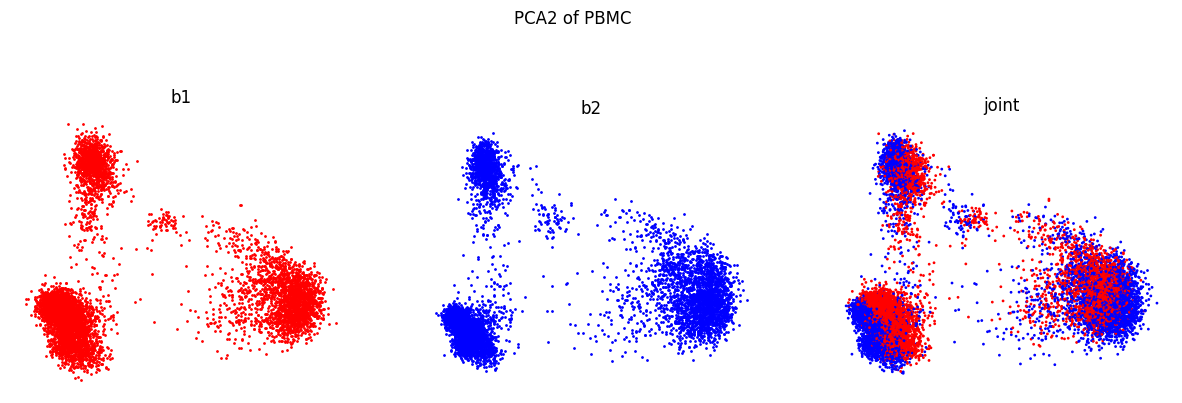

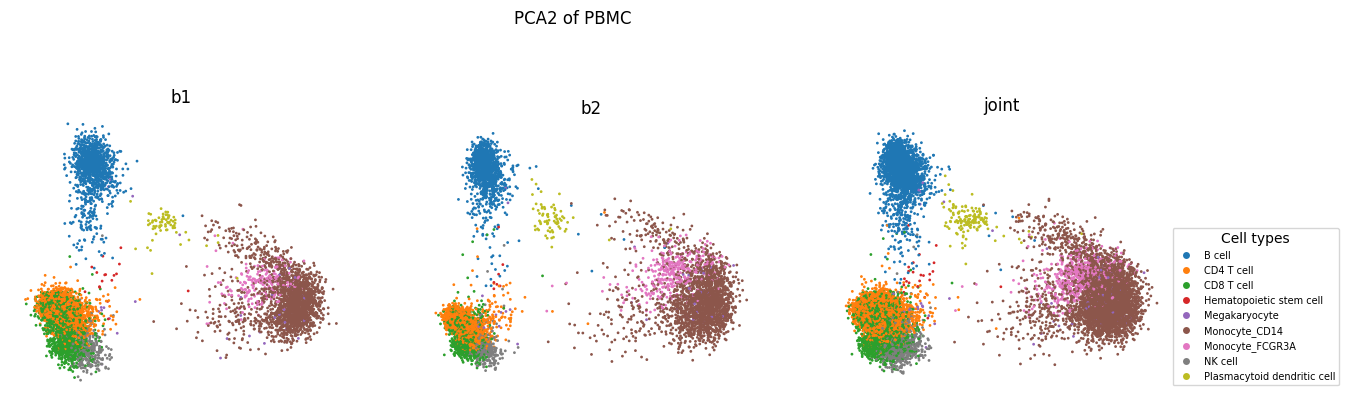

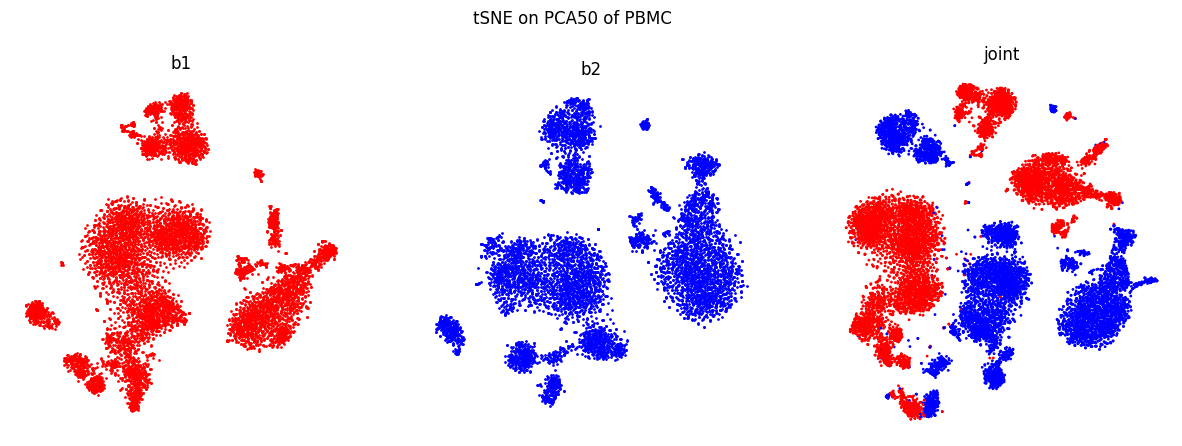

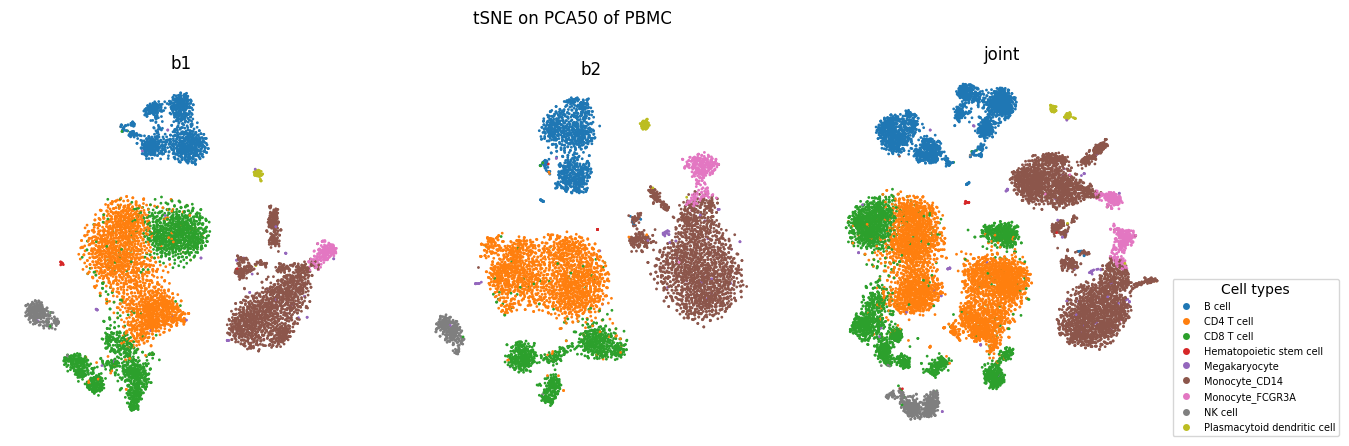

In [11]:
plot_variant(out_all, fig_dir=fig_path);

## Round trip

Check that the saved arrays read back the way the `compute_aligned_*` scripts expect
(`X1.npy` / `X2.npy` / `labels1.npy` / `labels2.npy` in `res_path`).

In [14]:
res_path = out_all["res_path"]
print(sorted(f for f in os.listdir(res_path) if not f.endswith(".txt.gz")))

X1 = np.load(os.path.join(res_path, "X1.npy"))
X2 = np.load(os.path.join(res_path, "X2.npy"))
C1 = np.load(os.path.join(res_path, "X1_counts.npy"))
C2 = np.load(os.path.join(res_path, "X2_counts.npy"))
y1 = np.load(os.path.join(res_path, "labels1.npy"))
y2 = np.load(os.path.join(res_path, "labels2.npy"))
names = np.load(os.path.join(res_path, "cell_type_names.npy"), allow_pickle=True)
batches = np.load(os.path.join(res_path, "dataset_names.npy"), allow_pickle=True)
features = pd.read_csv(os.path.join(res_path, "features.txt"))["gene"].to_list()
P1 = np.load(os.path.join(res_path, "X1_pca50.npy"))
P2 = np.load(os.path.join(res_path, "X2_pca50.npy"))
assert (P1.shape[0], P2.shape[0]) == (X1.shape[0], X2.shape[0]), "PCA misses cells"

print("X:", X1.shape, X2.shape, " counts:", C1.shape, C2.shape)
print("labels:", y1.shape, y2.shape, " features:", len(features))
print("batches:", list(batches), " types:", list(names))
print("PCA:", P1.shape, P2.shape)

['X1.npy', 'X1_counts.npy', 'X1_pca50.npy', 'X2.npy', 'X2_counts.npy', 'X2_pca50.npy', 'cell_type_names.npy', 'cells_metadata.csv', 'combined_1000genes.h5ad', 'dataset_names.npy', 'features.txt', 'labels1.npy', 'labels2.npy', 'pca50_joint.npy']
X: (8098, 1000) (7378, 1000)  counts: (8098, 1000) (7378, 1000)
labels: (8098,) (7378,)  features: 1000
batches: [np.str_('b1'), np.str_('b2')]  types: ['B cell', 'CD4 T cell', 'CD8 T cell', 'Hematopoietic stem cell', 'Megakaryocyte', 'Monocyte_CD14', 'Monocyte_FCGR3A', 'NK cell', 'Plasmacytoid dendritic cell']
PCA: (8098, 50) (7378, 50)
